# Natural Gas Pipelines — Africa & USA: Trade Flows, Infrastructure and Energy Dependency

This notebook explores three World Bank indicators for the ten African pipeline
countries in scope (Algeria, Nigeria, Egypt, Libya, Tanzania, Mozambique, Ghana,
Cameroon, Gabon, Angola) and the United States:

| Indicator | Code | Meaning |
|---|---|---|
| Gas share of electricity | `EG.ELC.NGAS.ZS` | Domestic dependence on gas-fired power |
| Natural gas rents | `NY.GDP.NGAS.RT.ZS` | Economic value of gas extraction (% of GDP) |
| Fuel exports | `TX.VAL.FUEL.ZS.UN` | Hydrocarbon concentration of merchandise trade |

It reads the raw CSVs in `data/raw/` directly (so it runs before the ETL pipeline
too) and adds the pipeline catalogue from `config/config.yaml`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
import yaml

pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data" / "raw").exists() else Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
with open(PROJECT_ROOT / "config" / "config.yaml", encoding="utf-8") as fh:
    CONFIG = yaml.safe_load(fh)

FOCUS = CONFIG["countries"]["focus"]
print("Project root:", PROJECT_ROOT)
print("Focus countries:", ", ".join(FOCUS))

Project root: /home/ubuntu/github_repos/Data-Analytic-Data-Engineering/2026-10-30_oil_gas_africa_usa_natural_gas_pipelines
Focus countries: DZA, NGA, EGY, LBY, TZA, MOZ, GHA, CMR, GAB, AGO, USA


## 1. Load and clean the raw World Bank extracts

In [2]:
FILES = {
    "ngas_electricity_pct": "wb_ngas_electricity_pct.csv",
    "ngas_rents_gdp_pct": "wb_ngas_rents_gdp_pct.csv",
    "fuel_exports_pct": "wb_fuel_exports_pct.csv",
}
LABELS = {
    "ngas_electricity_pct": "Gas share of electricity (%)",
    "ngas_rents_gdp_pct": "Natural gas rents (% of GDP)",
    "fuel_exports_pct": "Fuel exports (% of merchandise exports)",
}

frames = {}
for key, fname in FILES.items():
    df = pd.read_csv(RAW_DIR / fname)
    df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
    df[key] = pd.to_numeric(df[key], errors="coerce")
    df = df.dropna(subset=["iso3", "year", key]).drop_duplicates(["iso3", "year"], keep="last")
    frames[key] = df
    print(f"{fname:32s} rows={len(df):4d} countries={df.iso3.nunique():3d} years={df.year.min()}-{df.year.max()}")

names = pd.concat([f[["iso3", "country_name"]] for f in frames.values()]).drop_duplicates("iso3")
names["short_name"] = names["country_name"].replace({"Egypt, Arab Rep.": "Egypt", "Congo, Rep.": "Congo"})
names["region"] = np.where(names["iso3"] == "USA", "USA", "Africa")

wb_ngas_electricity_pct.csv      rows=  76 countries= 21 years=2021-2025
wb_ngas_rents_gdp_pct.csv        rows= 105 countries= 21 years=2017-2021
wb_fuel_exports_pct.csv          rows=  80 countries= 19 years=2021-2025


In [3]:
panel = None
for key, df in frames.items():
    sub = df[["iso3", "year", key]]
    panel = sub if panel is None else panel.merge(sub, on=["iso3", "year"], how="outer")
panel = panel.merge(names, on="iso3", how="left").sort_values(["iso3", "year"])
focus_panel = panel[panel["iso3"].isin(FOCUS)].copy()


def latest(df, key):
    sub = df.dropna(subset=[key]).sort_values("year").groupby("iso3").tail(1)
    return sub[["iso3", "short_name", "region", "year", key]]


latest_focus = (
    latest(focus_panel, "ngas_electricity_pct")
    .merge(latest(focus_panel, "ngas_rents_gdp_pct")[["iso3", "ngas_rents_gdp_pct"]], on="iso3", how="outer")
    .merge(latest(focus_panel, "fuel_exports_pct")[["iso3", "fuel_exports_pct"]], on="iso3", how="outer")
)
latest_focus["short_name"] = latest_focus["iso3"].map(names.set_index("iso3")["short_name"])
latest_focus["region"] = latest_focus["iso3"].map(names.set_index("iso3")["region"])
latest_focus.round(2)

,iso3,short_name,region,year,ngas_electricity_pct,ngas_rents_gdp_pct,fuel_exports_pct
0,AGO,Angola,Africa,2024,4.66,1.01,91.50
1,CMR,Cameroon,Africa,2024,10.67,0.58,54.07
2,DZA,Algeria,Africa,2024,98.98,8.00,93.14
3,EGY,Egypt,Africa,2024,76.86,2.05,9.79
4,GAB,Gabon,Africa,2024,38.81,0.27,53.99
5,GHA,Ghana,Africa,2024,59.38,0.37,8.80
6,LBY,Libya,Africa,2024,69.52,4.58,NaN
7,MOZ,Mozambique,Africa,2024,15.30,3.57,54.22
8,NGA,Nigeria,Africa,2024,72.87,1.16,85.90
9,TZA,Tanzania,Africa,2024,49.05,0.22,1.30


## 2. Gas-fired power dependency (seaborn)

How much of each country's electricity comes from natural gas in the latest
reported year? The USA is highlighted for comparison.

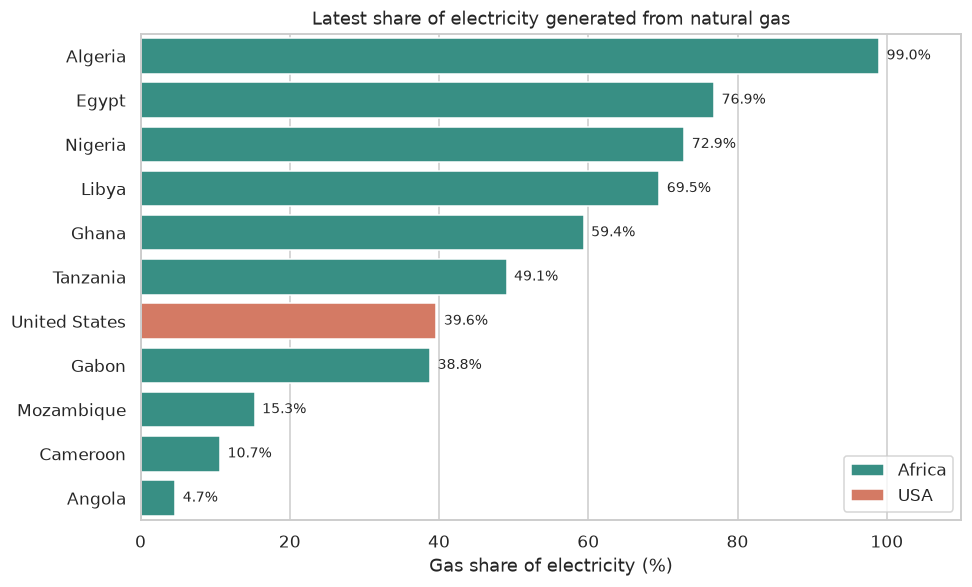

In [4]:
elec = latest_focus.dropna(subset=["ngas_electricity_pct"]).sort_values("ngas_electricity_pct", ascending=False)
palette = {"Africa": "#2a9d8f", "USA": "#e76f51"}

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=elec, y="short_name", x="ngas_electricity_pct", hue="region", dodge=False, palette=palette, ax=ax)
for i, v in enumerate(elec["ngas_electricity_pct"]):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set(xlabel=LABELS["ngas_electricity_pct"], ylabel="", xlim=(0, 110),
       title="Latest share of electricity generated from natural gas")
ax.legend(title="")
plt.tight_layout()
plt.show()

## 3. Natural gas rents over time (matplotlib)

Gas rents measure the value of gas production above extraction cost, relative
to GDP — a proxy for how much the economy earns from gas sold through pipelines
and LNG.

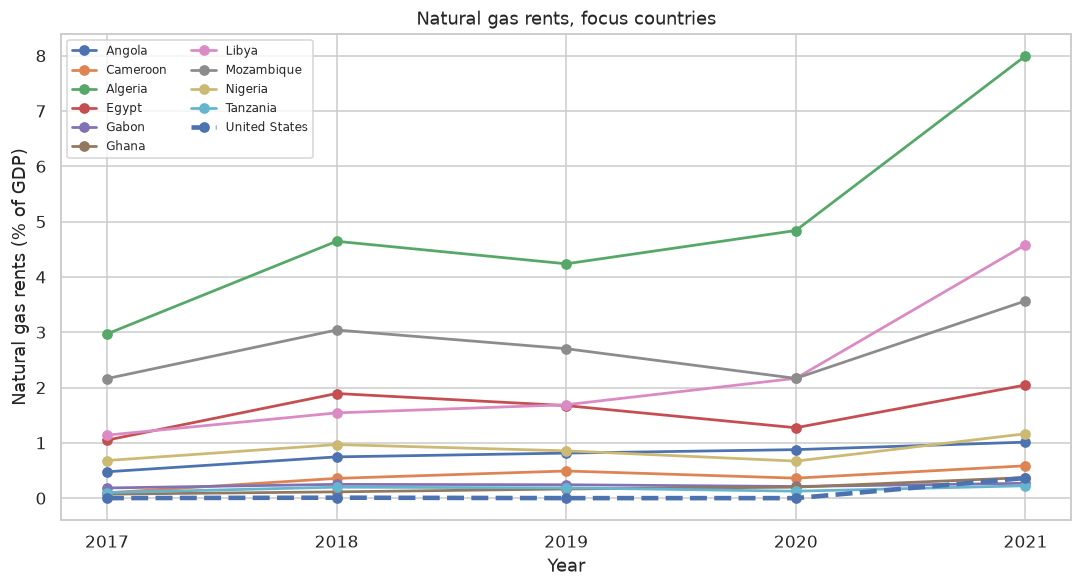

In [5]:
rents = focus_panel.dropna(subset=["ngas_rents_gdp_pct"])
fig, ax = plt.subplots(figsize=(10, 5.5))
for iso3, grp in rents.groupby("iso3"):
    is_usa = iso3 == "USA"
    ax.plot(grp["year"].astype(int), grp["ngas_rents_gdp_pct"], marker="o",
            linewidth=3 if is_usa else 1.8, linestyle="--" if is_usa else "-",
            label=grp["short_name"].iloc[0])
ax.set(xlabel="Year", ylabel=LABELS["ngas_rents_gdp_pct"], title="Natural gas rents, focus countries")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(ncol=2, fontsize=8, frameon=True)
plt.tight_layout()
plt.show()

## 4. Fuel export concentration heatmap (seaborn)

Share of merchandise exports made up of fuels (oil, gas, coal) by year. Darker
cells mean trade revenue is more concentrated in hydrocarbons.

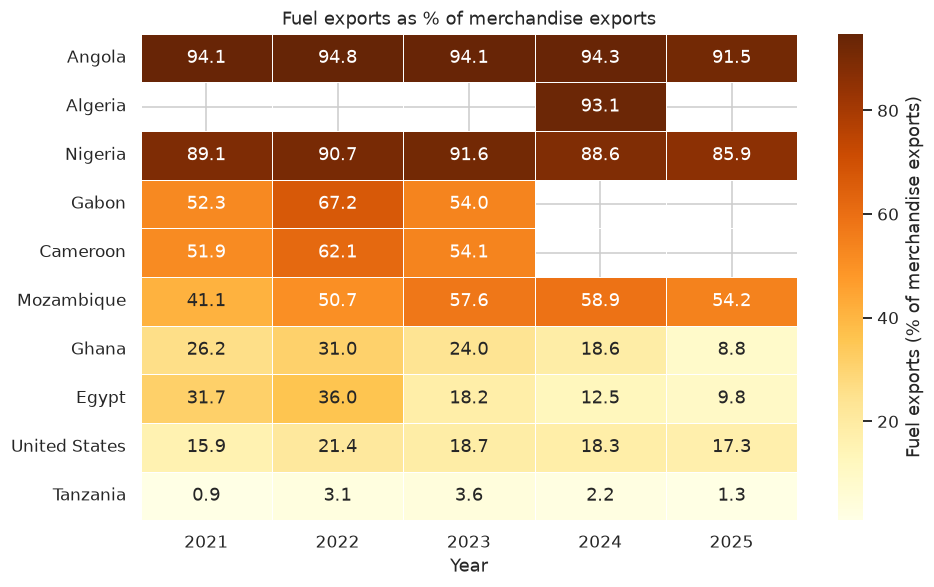

Focus countries without fuel-export data: ['LBY']


In [6]:
fuel = focus_panel.dropna(subset=["fuel_exports_pct"])
heat = fuel.pivot_table(index="short_name", columns="year", values="fuel_exports_pct")
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrBr", linewidths=0.5,
            cbar_kws={"label": LABELS["fuel_exports_pct"]}, ax=ax)
ax.set(xlabel="Year", ylabel="", title="Fuel exports as % of merchandise exports")
plt.tight_layout()
plt.show()
missing = sorted(set(FOCUS) - set(fuel["iso3"]))
print("Focus countries without fuel-export data:", missing or "none")

## 5. Domestic dependence vs export exposure (plotly)

Each bubble is a country: x = gas share of power, y = fuel share of exports,
bubble size = gas rents. Top-right countries depend on hydrocarbons both at home
and abroad.

In [7]:
bubble = latest_focus.dropna(subset=["ngas_electricity_pct", "fuel_exports_pct"]).copy()
bubble["rents_for_size"] = bubble["ngas_rents_gdp_pct"].fillna(0).clip(lower=0.05)
fig = px.scatter(
    bubble, x="ngas_electricity_pct", y="fuel_exports_pct", size="rents_for_size",
    color="region", text="short_name", size_max=55,
    color_discrete_map={"Africa": "#2a9d8f", "USA": "#e76f51"},
    labels={"ngas_electricity_pct": LABELS["ngas_electricity_pct"],
            "fuel_exports_pct": LABELS["fuel_exports_pct"],
            "rents_for_size": "Gas rents (% GDP)"},
    hover_data={"ngas_rents_gdp_pct": ":.2f", "rents_for_size": False},
    title="Gas power dependence vs fuel export exposure (bubble = gas rents)",
)
fig.update_traces(textposition="top center")
fig.add_hline(y=50, line_dash="dot", line_color="grey")
fig.add_vline(x=50, line_dash="dot", line_color="grey")
fig.update_layout(height=550)
fig.show()

## 6. Africa vs USA — regional averages (matplotlib)

Average of each indicator across the African focus countries compared with the
USA, using each country's latest reported year.

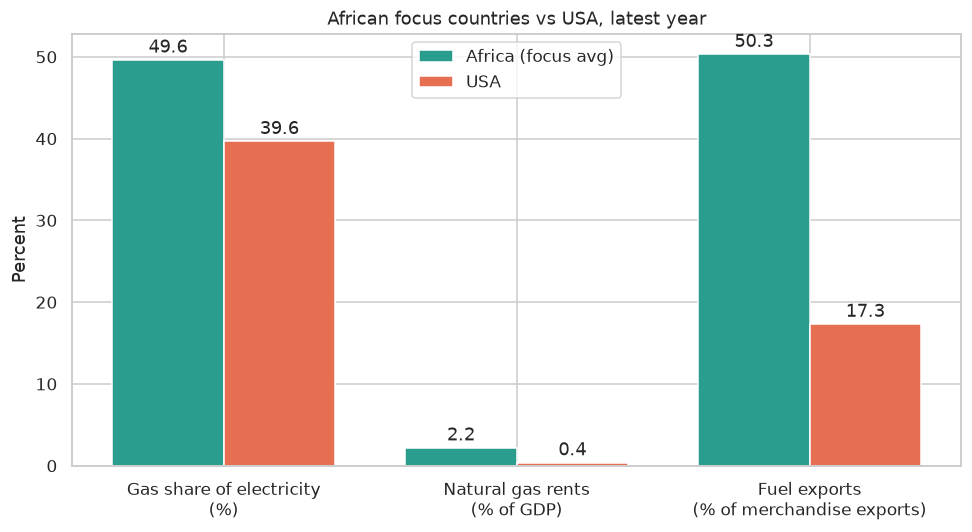

In [8]:
indicators = list(FILES)
africa_avg = latest_focus[latest_focus["region"] == "Africa"][indicators].mean()
usa_vals = latest_focus[latest_focus["region"] == "USA"][indicators].mean()

x = np.arange(len(indicators))
width = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - width / 2, africa_avg.values, width, label="Africa (focus avg)", color="#2a9d8f")
b2 = ax.bar(x + width / 2, usa_vals.values, width, label="USA", color="#e76f51")
ax.bar_label(b1, fmt="%.1f", padding=2)
ax.bar_label(b2, fmt="%.1f", padding=2)
ax.set_xticks(x, [LABELS[k].replace(" (", "\n(") for k in indicators])
ax.set(ylabel="Percent", title="African focus countries vs USA, latest year")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Pipeline infrastructure catalogue (plotly)

Approximate nameplate capacity of major pipelines originating in the focus
countries (from `config/config.yaml`). The USA's Transco trunkline is shown
separately as a scale reference.

In [9]:
pipes = pd.DataFrame(CONFIG["reference_pipelines"])
pipes["origin"] = pipes["origin_iso3"].map(names.set_index("iso3")["short_name"]).fillna(pipes["origin_iso3"])
african = pipes[pipes["origin_iso3"] != "USA"].sort_values("capacity_bcm_y")

fig = px.bar(
    african, x="capacity_bcm_y", y="name", color="status", orientation="h",
    hover_data=["origin", "destination", "length_km", "start_year"],
    labels={"capacity_bcm_y": "Capacity (bcm/year, approx.)", "name": ""},
    title="Major African gas pipelines by capacity and status",
)
fig.update_layout(height=500, legend_title_text="Status")
fig.show()

usa = pipes[pipes["origin_iso3"] == "USA"].iloc[0]
print(f"Scale reference: {usa['name']} ~{usa['capacity_bcm_y']:.0f} bcm/y vs "
      f"{african['capacity_bcm_y'].sum():.1f} bcm/y across all {len(african)} African pipelines listed.")

Scale reference: Transcontinental (Transco) ~190 bcm/y vs 114.8 bcm/y across all 9 African pipelines listed.


## 8. Composite energy-dependency score (matplotlib)

Mean of the available indicators per country, with gas rents multiplied by 10
(capped at 100) so all three sit on a comparable 0–100 range.

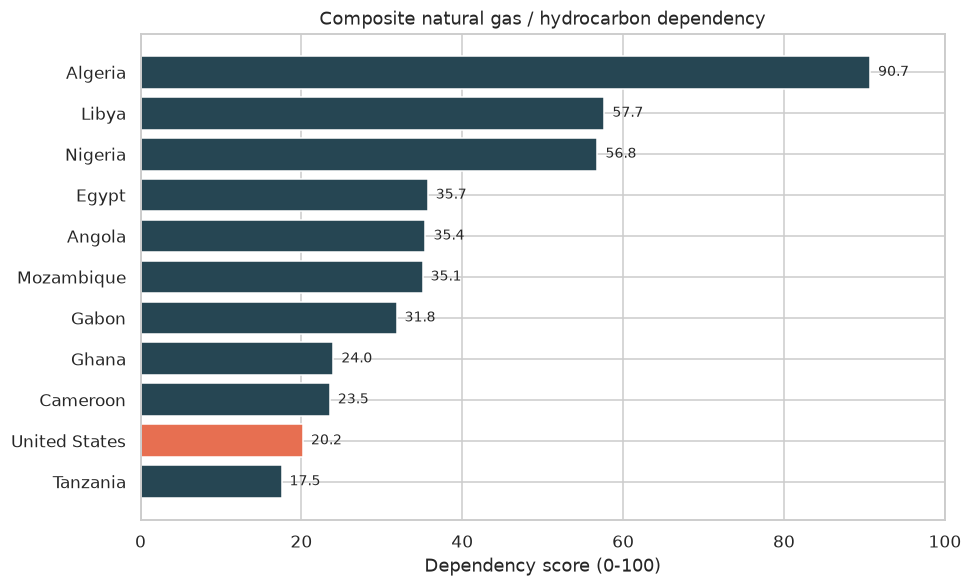

,short_name,ngas_electricity_pct,fuel_exports_pct,ngas_rents_gdp_pct,dependency_score
0,Algeria,98.98,93.14,8.00,90.69
1,Libya,69.52,NaN,4.58,57.66
2,Nigeria,72.87,85.90,1.16,56.80
3,Egypt,76.86,9.79,2.05,35.70
4,Angola,4.66,91.50,1.01,35.43
5,Mozambique,15.30,54.22,3.57,35.06
6,Gabon,38.81,53.99,0.27,31.83
7,Ghana,59.38,8.80,0.37,23.97
8,Cameroon,10.67,54.07,0.58,23.53
9,United States,39.65,17.30,0.36,20.19


In [10]:
score = latest_focus.copy()
score["rents_scaled"] = (score["ngas_rents_gdp_pct"] * 10).clip(upper=100)
score["dependency_score"] = score[["ngas_electricity_pct", "fuel_exports_pct", "rents_scaled"]].mean(axis=1)
score = score.sort_values("dependency_score")

colors = ["#e76f51" if r == "USA" else "#264653" for r in score["region"]]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(score["short_name"], score["dependency_score"], color=colors)
for y, v in enumerate(score["dependency_score"]):
    ax.text(v + 1, y, f"{v:.1f}", va="center", fontsize=9)
ax.set(xlabel="Dependency score (0-100)", xlim=(0, 100),
       title="Composite natural gas / hydrocarbon dependency")
plt.tight_layout()
plt.show()
score[["short_name", "ngas_electricity_pct", "fuel_exports_pct", "ngas_rents_gdp_pct", "dependency_score"]] \
    .sort_values("dependency_score", ascending=False).round(2).reset_index(drop=True)

## 9. Key findings (computed from the data above)

In [11]:
top_power = elec.iloc[0]
usa_row = latest_focus[latest_focus["iso3"] == "USA"].iloc[0]
top_rent = latest_focus.sort_values("ngas_rents_gdp_pct", ascending=False).iloc[0]
over_50 = latest_focus[latest_focus["fuel_exports_pct"] > 50]["short_name"].tolist()
top_score = score.sort_values("dependency_score", ascending=False).iloc[0]

findings = [
    f"{top_power.short_name} generates {top_power.ngas_electricity_pct:.1f}% of its electricity from gas "
    f"({int(top_power.year)}), vs {usa_row.ngas_electricity_pct:.1f}% in the USA.",
    f"{top_rent.short_name} has the highest gas rents at {top_rent.ngas_rents_gdp_pct:.2f}% of GDP; "
    f"the USA's are {usa_row.ngas_rents_gdp_pct:.2f}%.",
    f"Fuels exceed half of merchandise exports in: {', '.join(over_50)}.",
    f"USA fuel exports are {usa_row.fuel_exports_pct:.1f}% of merchandise exports - large in volume, "
    "but diversified relative to African producers.",
    f"Highest composite dependency score: {top_score.short_name} ({top_score.dependency_score:.1f}/100).",
]
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

1. Algeria generates 99.0% of its electricity from gas (2024), vs 39.6% in the USA.
2. Algeria has the highest gas rents at 8.00% of GDP; the USA's are 0.36%.
3. Fuels exceed half of merchandise exports in: Angola, Cameroon, Algeria, Gabon, Mozambique, Nigeria.
4. USA fuel exports are 17.3% of merchandise exports - large in volume, but diversified relative to African producers.
5. Highest composite dependency score: Algeria (90.7/100).


### Notes and limitations

* World Bank gas-rent estimates in this extract end in 2021; electricity and
  trade series run to 2024/2025.
* Libya has no fuel-export observations in the extract, so its composite score
  is based on two indicators.
* Pipeline capacities are approximate nameplate figures and do not reflect
  actual throughput (e.g. Maghreb-Europe flows from Algeria were halted in 2021).